# UCS420 Assignment 7 - NLP-I

In [1]:
ROLL_NO = 1024170344
NAME = "Ansh Sharma"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170344   Name: Ansh Sharma   Fingerprint: 335A6D2A   Tickets: 16

Ticket_ID                                                                            Ticket_Text
      T01                                              The printer won't print; it isn't jammed.
      T02          Python crashes while opening after restarting the system. Can you check this?
      T03 I am unable to use the WiFi when connected to campus Wi-Fi. I don't know what changed.
      T04                                 The server failed to open. I have tried several times!
      T05                                                     Dr. Rao's lab PC (No. 14) is down.
      T06       I am unable to use the password after restarting the system. Can you check this?
      T07                                    The Matlab is showing an error. Can you check this?
      T08                                                 Only 2 of 30 PCs boot after 3.5 hours.
      T09                                   

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
processed = [process_ticket(text) for text in df["Ticket_Text"]]
rows = []
for ticket_id, result in zip(df["Ticket_ID"], processed):
    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })
preprocessing_table = pd.DataFrame(rows)
total_row = {"Ticket_ID": "TOTAL"}
for column in preprocessing_table.columns[1:]:
    total_row[column] = preprocessing_table[column].sum()
preprocessing_table = pd.concat([preprocessing_table, pd.DataFrame([total_row])], ignore_index=True)
display(preprocessing_table)

selected_ticket = df.iloc[0]
selected_result = processed[0]
print(selected_ticket["Ticket_ID"])
print("Tokens:", selected_result["tokens"])
print("Punctuation tokens:", selected_result["punct"])
print("Stopwords:", selected_result["stops"])
print("Final tokens:", selected_result["final"])

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,1,11,2,3,10,6
1,T02,2,14,2,6,14,6
2,T03,2,20,2,9,17,9
3,T04,2,12,2,4,12,6
4,T05,2,13,4,3,12,6
5,T06,2,17,2,9,16,6
6,T07,2,12,2,6,12,4
7,T08,1,10,1,3,10,6
8,T09,2,7,2,3,6,2
9,T10,2,11,2,5,11,4


T01
Tokens: ['the', 'printer', 'wo', "n't", 'print', ';', 'it', 'is', "n't", 'jammed', '.']
Punctuation tokens: [';', '.']
Stopwords: ['the', 'it', 'is']
Final tokens: ['printer', 'wo', "n't", 'print', "n't", 'jammed']


The unusual final tokens mainly come from contractions and identifiers being split by `word_tokenize`.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

raw_tickets = df["Ticket_Text"].tolist()
raw_text = "\n".join(raw_tickets)
long_word_pattern = r"\b[A-Za-z]{6,}\b"
number_pattern = r"(?<![\w.])\d+(?:,\d{3})*(?:\.\d+)*(?!\w|\.\d)"
capitalized_pattern = r"\b[A-Z][A-Za-z]*(?:-[A-Za-z]+)*\b"
vowel_word_pattern = r"\b[AEIOUaeiou][A-Za-z]*(?:-[A-Za-z]+)*\b"
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"(?:https?://|www\.)[A-Za-z0-9.-]+\.[A-Za-z]{2,}(?:/[A-Za-z0-9._~:/?#\[\]@!$&'()*+,;=%-]*)?"
phone_pattern = r"(?<!\w)(?:\+91[ -]?)?\d{5}[ -]?\d{5}(?!\w)|(?<!\w)\d{4}-\d{3}-\d{4}(?!\w)"

print("Words longer than 5 letters:", re.findall(long_word_pattern, raw_text))
print("Numbers:", re.findall(number_pattern, raw_text))
print("Capitalized words:", re.findall(capitalized_pattern, raw_text))
print("Words beginning with a vowel:", re.findall(vowel_word_pattern, raw_text))

for line in TEST_LINES:
    print("TEST_LINE:", re.findall(long_word_pattern, line), re.findall(number_pattern, line),
          re.findall(capitalized_pattern, line), re.findall(vowel_word_pattern, line))

for line in TEST_LINES:
    replaced = re.sub(email_pattern, "<EMAIL>", line)
    replaced = re.sub(url_pattern, "<URL>", replaced)
    replaced = re.sub(phone_pattern, "<PHONE>", replaced)
    print(replaced)

Words longer than 5 letters: ['printer', 'jammed', 'Python', 'crashes', 'opening', 'restarting', 'system', 'unable', 'connected', 'campus', 'changed', 'server', 'failed', 'several', 'unable', 'password', 'restarting', 'system', 'Matlab', 'showing', 'password', 'failed', 'server', 'connected', 'campus', 'changed', 'MATLAB', 'running', 'slowly', 'uploading', 'Please', 'crashes', 'opening', 'during', 'Please', 'reinstalled', 'mobile', 'hotspot', 'crashes', 'opening', 'latest', 'update', 'another', 'computer', 'stopped', 'responding', 'another', 'solution']
Numbers: ['14', '2', '30', '3.5', '1023', '03', '021']
Capitalized words: ['The', 'Python', 'Can', 'I', 'WiFi', 'Wi-Fi', 'I', 'The', 'I', 'Dr', 'Rao', 'PC', 'No', 'I', 'Can', 'The', 'Matlab', 'Can', 'Only', 'PCs', 'My', 'The', 'Can', 'I', 'Wi-Fi', 'I', 'MATLAB', 'Please', 'E-mail', 'Please', 'I', 'LMS', 'I', 'Can', 'VPN', 'It', 'The', 'Is']
Words beginning with a vowel: ['it', 'isn', 'opening', 'after', 'I', 'am', 'unable', 'use', 'I', 

capitalized_words = re.findall(capitalized_pattern, raw_text)
sentence_initial = []
for ticket in raw_tickets:
    for sentence in sent_tokenize(ticket):
        match = re.match(capitalized_pattern, sentence)
        if match:
            sentence_initial.append(match.group())
print(f"{len(sentence_initial)} of {len(capitalized_words)} capitalized matches begin a sentence.")

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer

token_pattern = r"(?:https?://|www\.)[A-Za-z0-9.-]+\.[A-Za-z]{2,}(?:/[A-Za-z0-9._~:/?#\[\]@!$&\'()*+,;=%-]*[A-Za-z0-9/#])?|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|(?:\+91[ -]?)?\d{5}[ -]?\d{5}|\d{4}-\d{3}-\d{4}|\d+(?:\.\d+)+|[A-Za-z]+(?:'[A-Za-z]+)?(?:-[A-Za-z]+(?:'[A-Za-z]+)?)*|\d+"
tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for line in TEST_LINES:
    print("Text:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

comparison = []
for ticket_id, ticket in zip(df["Ticket_ID"], raw_tickets):
    custom_tokens = my_tokenize(ticket)
    nltk_tokens = word_tokenize(ticket)
    comparison.append({"Ticket_ID": ticket_id, "Different": custom_tokens != nltk_tokens, "my_tokenize": custom_tokens, "word_tokenize": nltk_tokens})
comparison_table = pd.DataFrame(comparison)
display(comparison_table)
print("Tickets tokenized differently:", comparison_table["Different"].sum())


Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
my_tokenize: ['The', 'state-of-the-art', 'lab

,Ticket_ID,Different,my_tokenize,word_tokenize
0,T01,True,"[The, printer, won't, print, it, isn't, jammed]","[The, printer, wo, n't, print, ;, it, is, n't,..."
1,T02,True,"[Python, crashes, while, opening, after, resta...","[Python, crashes, while, opening, after, resta..."
2,T03,True,"[I, am, unable, to, use, the, WiFi, when, conn...","[I, am, unable, to, use, the, WiFi, when, conn..."
3,T04,True,"[The, server, failed, to, open, I, have, tried...","[The, server, failed, to, open, ., I, have, tr..."
4,T05,True,"[Dr, Rao's, lab, PC, No, 14, is, down]","[Dr., Rao, 's, lab, PC, (, No, ., 14, ), is, d..."
5,T06,True,"[I, am, unable, to, use, the, password, after,...","[I, am, unable, to, use, the, password, after,..."
6,T07,True,"[The, Matlab, is, showing, an, error, Can, you...","[The, Matlab, is, showing, an, error, ., Can, ..."
7,T08,True,"[Only, 2, of, 30, PCs, boot, after, 3.5, hours]","[Only, 2, of, 30, PCs, boot, after, 3.5, hours..."
8,T09,True,"[My, roll, no, is, 1023, 03, 021]","[My, roll, no, ., is, 1023-03-021, .]"
9,T10,True,"[The, password, failed, to, open, Can, you, ch...","[The, password, failed, to, open, ., Can, you,..."


Tickets tokenized differently: 16


The custom tokenizer keeps `isn't` together, while `word_tokenize` splits it into `is` and `n't`. It also keeps `state-of-the-art` as one token and keeps decimals such as `95.5` intact. In `word_tokenize`, contractions and punctuation are split into separate tokens. URLs, email addresses and phone numbers also stay together with my tokenizer.


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

unique_final_tokens = list(dict.fromkeys(token for result in processed for token in result["final"]))
porter = PorterStemmer()
lancaster = LancasterStemmer()
# Choose a suffix after checking the dataset words. The assignment asks for at
# least two examples, so prefer a suffix that occurs on at least two unique tokens.
chosen_suffix = "ing"
suffix_words = [word for word in unique_final_tokens if word.endswith(chosen_suffix)]
if len(suffix_words) < 2:
    raise ValueError("The selected suffix must occur in at least two dataset words.")
regexp_stemmer = RegexpStemmer(chosen_suffix + r"$", min=4)
lemmatizer = WordNetLemmatizer()

def wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

tagged_tokens = nltk.pos_tag(unique_final_tokens)
stem_rows = []
for word, tag in tagged_tokens:
    stem_rows.append({
        "Word": word,
        "POS": tag,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp_stemmer.stem(word),
        "Lemma": lemmatizer.lemmatize(word, wordnet_pos(tag))
    })
stemming_table = pd.DataFrame(stem_rows)
different_outputs = stemming_table[stemming_table[["Porter", "Lancaster", "Regexp", "Lemma"]].nunique(axis=1) > 1]
display(different_outputs)
suffix_words = [word for word in unique_final_tokens if word.endswith(chosen_suffix)]
print(f"RegexpStemmer rule: {chosen_suffix}$; dataset words with this suffix ({len(suffix_words)}):", suffix_words)

,Word,POS,Porter,Lancaster,Regexp,Lemma
0,printer,NN,printer,print,printer,printer
4,jammed,JJ,jam,jam,jammed,jammed
6,crashes,NNS,crash,crash,crashes,crash
7,opening,VBG,open,op,open,open
11,unable,JJ,unabl,un,unable,unable
12,use,NN,use,us,use,use
13,wifi,NN,wifi,wif,wifi,wifi
14,connected,VBN,connect,connect,connected,connect
15,campus,JJ,campu,camp,campus,campus
16,wi-fi,NN,wi-fi,wi-f,wi-fi,wi-fi


RegexpStemmer rule: ing$; dataset words with this suffix (6): ['opening', 'restarting', 'showing', 'running', 'uploading', 'responding']


I chose `ing$` because it occurs in words such as `opening`, `restarting` and `uploading`. Lancaster over-stems `several` to `sev`. The regexp rule is simpler and leaves irregular forms unchanged.


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,209,95,0.4545
1,S2,176,89,0.5057
2,S3,97,65,0.6701
3,S4,97,63,0.6495


Top 10 words in S1: [('.', 23), ('the', 14), ('i', 8), ('is', 6), ('?', 6), ('to', 6), ("n't", 5), ('can', 5), ('you', 5), ('check', 5)]
Top 10 words in S3: [("n't", 5), ('check', 5), ('crashes', 3), ('opening', 3), ('use', 3), ('open', 3), ('restarting', 2), ('system', 2), ('unable', 2), ('connected', 2)]


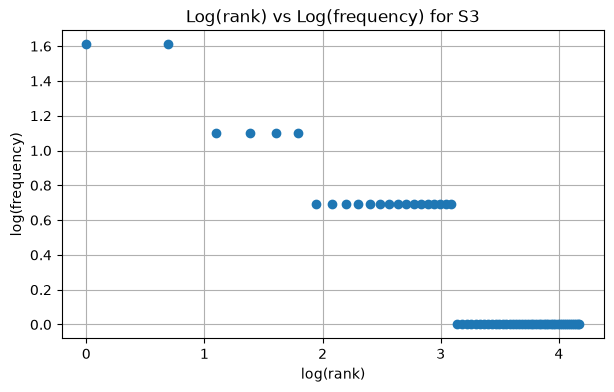

Top 5 bigrams in S1: [(('.', 'can'), 5), (('can', 'you'), 5), (('you', 'check'), 5), (('check', 'this'), 5), (('this', '?'), 5)]
Top 5 bigrams in S3: [(('crashes', 'opening'), 3), (('restarting', 'system'), 2), (('system', 'check'), 2), (('unable', 'use'), 2), (('connected', 'campus'), 2)]


In [9]:
from collections import Counter
from nltk.util import bigrams
import matplotlib.pyplot as plt
import numpy as np

s1 = [token for result in processed for token in result["tokens"]]
s2 = [token for token in s1 if not is_punct(token)]
s3 = [token for result in processed for token in result["final"]]
s4 = [porter.stem(token) for token in s3]

def corpus_row(label, tokens):
    return {"Corpus": label, "Total Tokens": len(tokens), "Unique Tokens": len(set(tokens)), "TTR": round(len(set(tokens)) / len(tokens), 4)}

statistics_table = pd.DataFrame([
    corpus_row("S1", s1),
    corpus_row("S2", s2),
    corpus_row("S3", s3),
    corpus_row("S4", s4)
])
display(statistics_table)

print("Top 10 words in S1:", Counter(s1).most_common(10))
print("Top 10 words in S3:", Counter(s3).most_common(10))

frequency = Counter(s3)
frequencies = sorted(frequency.values(), reverse=True)
ranks = np.arange(1, len(frequencies) + 1)
plt.figure(figsize=(7, 4))
plt.plot(np.log(ranks), np.log(frequencies), marker="o", linestyle="none")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log(rank) vs Log(frequency) for S3")
plt.grid(True)
plt.show()

print("Top 5 bigrams in S1:", Counter(bigrams(s1)).most_common(5))
print("Top 5 bigrams in S3:", Counter(bigrams(s3)).most_common(5))

The TTR changes because punctuation and stopwords are removed to form S3, then Porter stemming combines related word forms in S4.

---
## Q6. Interpretation


(a) The TTR changes as punctuation and stopwords are removed, and stemming merges related forms. The unique-token count and total-token count therefore change across S1-S4.

(b) `isn't` is one token with my tokenizer but becomes `is` and `n't` with `word_tokenize`.

(c) Lancaster changes `several` to `sev`, which is not a useful word form.

(d) `changed` is tagged as a verb and lemmatized to `change`. Porter stemming gives `chang`, which is not the dictionary form.
